In [1]:
from __future__ import annotations

from typing import Any, Callable, NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import spacecore as sc

In [2]:
def as_numpy(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def scalar_value(x) -> float:
    return float(as_numpy(x).item())


class RiemannianManifoldSpace(sc.VectorSpace):
    """Vector-backed Riemannian manifold base class."""

    def retract(self, x: Any, v: Any) -> Any:
        raise NotImplementedError("Subclasses must implement retract(x, v).")

    def proj_tangent(self, x: Any, v: Any) -> Any:
        return v

    def metric(self, x: Any, u: Any, v: Any) -> Any:
        return super().inner(u, v)

    def tangent_norm(self, x: Any, v: Any) -> Any:
        return self.ops.sqrt(self.ops.real(self.metric(x, v, v)))

    def zero_tangent(self, x: Any) -> Any:
        return self.zeros()

    def riemannian_grad(self, x: Any, euclidean_grad: Any) -> Any:
        return self.proj_tangent(x, euclidean_grad)

    def parallel_transport(self, x: Any, y: Any, v: Any) -> Any:
        return self.proj_tangent(y, v)

In [3]:
class RiemannianGradientDescentResult(NamedTuple):
    x: Any
    converged: bool
    num_iters: int
    final_grad_norm: float
    trajectory: tuple[Any, ...]
    values: tuple[float, ...]


def riemannian_gradient_descent(
    manifold: RiemannianManifoldSpace,
    objective: Callable[[Any], Any],
    x0: Any,
    *,
    grad: Callable[[Any], Any] | None = None,
    step_size: float = 1.0,
    maxiter: int = 100,
    tol: float = 1e-8,
    line_search: bool = False,
    backtracking: float = 0.5,
    armijo: float = 1e-4,
    min_step_size: float = 1e-12,
    record_trajectory: bool = False,
) -> RiemannianGradientDescentResult:
    if grad is None:
        if hasattr(objective, "riemannian_grad"):
            grad = objective.riemannian_grad
        elif hasattr(objective, "grad"):
            grad = objective.grad
        else:
            raise ValueError("Pass grad=... or provide objective.grad/riemannian_grad.")

    x = x0
    trajectory = [x] if record_trajectory else []
    values = [scalar_value(objective(x))] if record_trajectory else []
    converged = False
    num_iters = 0

    for iteration in range(maxiter):
        g = grad(x)
        grad_norm = scalar_value(manifold.tangent_norm(x, g))
        if grad_norm <= tol:
            converged = True
            break

        eta = step_size
        f_x = scalar_value(objective(x)) if line_search else None
        while True:
            candidate = manifold.retract(x, manifold.scale(-eta, g))
            if not line_search:
                break

            f_candidate = scalar_value(objective(candidate))
            if f_candidate <= f_x - armijo * eta * grad_norm**2:
                break
            eta *= backtracking
            if eta < min_step_size:
                break

        x = candidate
        num_iters = iteration + 1
        if record_trajectory:
            trajectory.append(x)
            values.append(scalar_value(objective(x)))

    final_grad_norm = scalar_value(manifold.tangent_norm(x, grad(x)))
    converged = converged or final_grad_norm <= tol
    return RiemannianGradientDescentResult(
        x=x,
        converged=converged,
        num_iters=num_iters,
        final_grad_norm=final_grad_norm,
        trajectory=tuple(trajectory),
        values=tuple(values),
    )

In [10]:
class SphereSpace(RiemannianManifoldSpace):
    """Unit sphere S^{n-1}."""

    def __init__(self, dim: int, ctx: sc.Context | str | None = None):
        super().__init__((dim,), ctx)
        self.dim = dim

    def retract(self, x, v):
        y = x + v
        return y / self.ops.norm(y, axis=-1, keepdims=True)

    def proj_tangent(self, x, v):
        return v - self.metric(x, x, v) * x

    def metric(self, x, u, v):
        return self.ops.sum(u * v, axis=-1)


class SphereObjective:
    def __init__(self, target, manifold: SphereSpace):
        self.target = manifold.ctx.asarray(target)
        self.manifold = manifold

    def __call__(self, x):
        return -self.manifold.ops.sum(x * self.target, axis=-1) + self.manifold.inner(x, x)

    def euclidean_grad(self, x):
        return -self.target

    def riemannian_grad(self, x):
        return self.manifold.riemannian_grad(x, self.euclidean_grad(x))

In [11]:
ctx = sc.Context(sc.NumpyOps(), dtype="float64")
sphere = SphereSpace(dim=3, ctx=ctx)

target = ctx.asarray([0.8, 0.6, 0.0])
target = target / ctx.ops.norm(target)

obj = SphereObjective(target, sphere)
x0 = ctx.asarray([0.0, 0.0, 1.0])

result = riemannian_gradient_descent(
    manifold=sphere,
    objective=obj,
    x0=x0,
    step_size=0.8,
    maxiter=80,
    tol=1e-8,
    line_search=True,
    record_trajectory=True,
)

print(f"Converged: {result.converged} in {result.num_iters} iterations")
print(f"Final gradient norm: {result.final_grad_norm:.2e}")
print(f"Final point: {as_numpy(result.x)}")
print(f"Dot product with target: {scalar_value(ctx.ops.sum(result.x * target)):.4f}")

Converged: True in 13 iterations
Final gradient norm: 8.13e-09
Final point: [8.00000000e-01 6.00000000e-01 8.12682582e-09]
Dot product with target: 1.0000


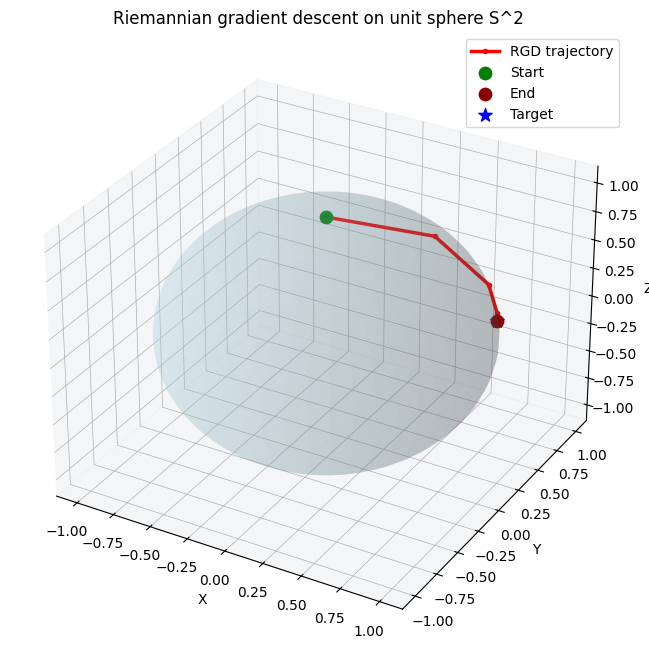

In [12]:
traj = np.stack([as_numpy(t) for t in result.trajectory])
target_np = as_numpy(target)

u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 50)
sx = np.outer(np.cos(u), np.sin(v))
sy = np.outer(np.sin(u), np.sin(v))
sz = np.outer(np.ones_like(u), np.cos(v))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(sx, sy, sz, alpha=0.2, color="lightblue", edgecolor="none")
ax.plot(
    traj[:, 0],
    traj[:, 1],
    traj[:, 2],
    color="red",
    linewidth=2.5,
    marker="o",
    markersize=3,
    label="RGD trajectory",
)
ax.scatter([traj[0, 0]], [traj[0, 1]], [traj[0, 2]], color="green", s=80, label="Start")
ax.scatter([traj[-1, 0]], [traj[-1, 1]], [traj[-1, 2]], color="darkred", s=80, label="End")
ax.scatter([target_np[0]], [target_np[1]], [target_np[2]], color="blue", s=100, marker="*", label="Target")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Riemannian gradient descent on unit sphere S^2")
ax.legend()
plt.show()

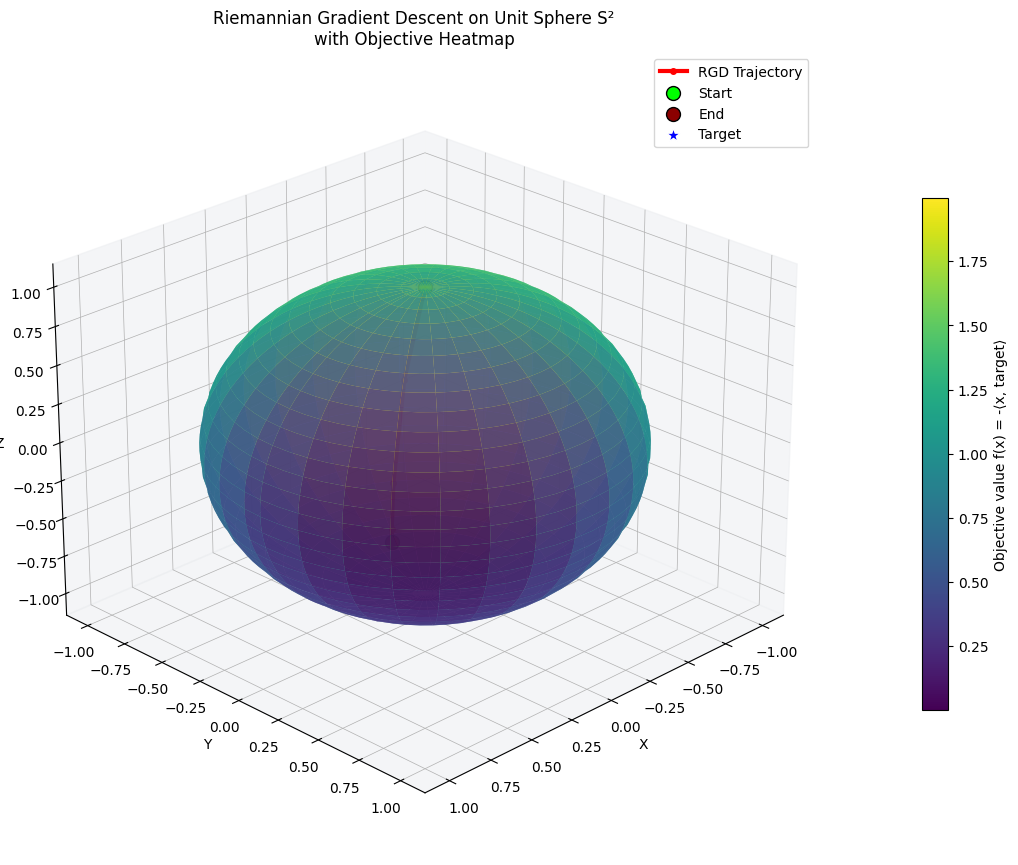

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import spacecore as sc

# Assuming these are already defined from previous cells:
# result, target, sphere, obj (SphereObjective), ctx

# Convert trajectory and target to numpy
traj = np.stack([np.asarray(t) for t in result.trajectory])   # use sc.as_numpy if available
target_np = np.asarray(target)

# ======================
# Generate sphere grid
# ======================
u = np.linspace(0, 2 * np.pi, 60)
v = np.linspace(0, np.pi, 60)
sx = np.outer(np.cos(u), np.sin(v))
sy = np.outer(np.sin(u), np.sin(v))
sz = np.outer(np.ones_like(u), np.cos(v))

# ======================
# Compute heatmap values (objective function)
# ======================
# Reshape grid points to (N, 3) for evaluation
points = np.stack([sx.ravel(), sy.ravel(), sz.ravel()], axis=1)   # shape (3600, 3)
points = ctx.asarray(points)

# Evaluate objective on the entire grid
obj_values = np.array([float(obj(p)) for p in points])   # obj is SphereObjective
obj_values = obj_values.reshape(sx.shape)

# Normalize for coloring
norm = Normalize(vmin=obj_values.min(), vmax=obj_values.max())

# ======================
# Plot
# ======================
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')

# Heatmap surface
surf = ax.plot_surface(
    sx, sy, sz,
    facecolors=plt.cm.viridis(norm(obj_values)),   # or plt.cm.plasma, coolwarm, etc.
    alpha=0.85,
    linewidth=0,
    antialiased=True,
    shade=False
)

# Optional colorbar
mappable = plt.cm.ScalarMappable(norm=norm, cmap='viridis')
mappable.set_array(obj_values)
cbar = fig.colorbar(mappable, ax=ax, shrink=0.6, pad=0.1)
cbar.set_label('Objective value f(x) = -⟨x, target⟩')

# Trajectory
ax.plot(
    traj[:, 0], traj[:, 1], traj[:, 2],
    color='red', linewidth=3, marker='o', markersize=4,
    label='RGD Trajectory'
)

# Start / End / Target
ax.scatter([traj[0, 0]], [traj[0, 1]], [traj[0, 2]],
           color='lime', s=100, label='Start', edgecolors='black', zorder=5)
ax.scatter([traj[-1, 0]], [traj[-1, 1]], [traj[-1, 2]],
           color='darkred', s=100, label='End', edgecolors='black', zorder=5)
ax.scatter([target_np[0]], [target_np[1]], [target_np[2]],
           color='blue', s=120, marker='*', label='Target', edgecolors='white', zorder=6)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Riemannian Gradient Descent on Unit Sphere S²\nwith Objective Heatmap')
ax.legend()

# Improve view angle
ax.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()